# Project 03: Feature Stability Under Distribution Shift

**Original statement (verbatim from LAB_Projects_ML.pdf):**

Train a model on historical data and evaluate on a future time slice with degraded performance. Task: Detect covariate shift; Identify unstable features; Retrain using only stable features and justify selection

**Dataset:** ONLY Combined12_0_4op7.csv (weather data). No other dataset is used.

**Canonical Google Drive path (used in Colab):** `/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv`

**Adaptation / limitation (read first):** Models can degrade when the input distribution changes even if the labelling rule is stable. This notebook measures shift, finds unstable features, and tests whether dropping them helps on the shifted domain.

## Part 1 — Introduction

There is no timestamp, so 'historical vs future' is approximated by a Wind_Bearing domain split (bearing <180 vs >=180), NOT a real time slice. Shift is therefore a domain shift, and that limitation is stated wherever results are discussed.

## Part 2 — Imports, Drive connection and dataset loading

The cell below mounts Drive in Colab. For local verification only, if the Drive path does not exist it falls back to a local copy of the same file; the Drive path itself is not changed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(8,4.5)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not in Colab (or Drive already mounted):", e)
DRIVE_PATH="/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv"
LOCAL_PATH="/home/hatch/workspace/user/files/Combined12_0_4op7.csv"
if os.path.exists(DRIVE_PATH):
    DATA_PATH=DRIVE_PATH
elif os.path.exists(LOCAL_PATH):
    DATA_PATH=LOCAL_PATH
    print("LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.")
else:
    DATA_PATH="Combined12_0_4op7.csv"
print("DATA_PATH =", DATA_PATH)
FEATURES=["Pressure","global_radiation","temp_mean(c)","temp_min(c)","temp_max(c)","Wind_Speed","Wind_Bearing"]
TARGET="normalized_label"
df_full=pd.read_csv(DATA_PATH)
print("Full shape:", df_full.shape)
print(df_full.dtypes.to_string())
print("Missing per column:\n", df_full.isna().sum().to_string())
print("Duplicates (full rows):", int(df_full.duplicated().sum()))
print("Class counts:\n", df_full[TARGET].value_counts(normalize=False).sort_index().to_string())
print("Class rates:\n", (df_full[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_string())
df_full.head()

Not in Colab (or Drive already mounted): No module named 'google.colab'
LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.
DATA_PATH = /home/hatch/workspace/user/files/Combined12_0_4op7.csv


Full shape: (533312, 8)
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing          int64
normalized_label      int64
Missing per column:
 Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0
Duplicates (full rows): 16264


Class counts:
 normalized_label
0    239241
1    155709
2     87533
3     50829
Class rates:
 normalized_label
0    44.86
1    29.20
2    16.41
3     9.53


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


## Part 3 — Domain split and shift detection

In [2]:
from scipy import stats
df=df_full.sample(n=40000, random_state=42).reset_index(drop=True)
df["domain"]=np.where(df["Wind_Bearing"]>=180,"target_domain_bearing>=180","source_domain_bearing<180")
src=df[df["domain"].str.startswith("source")]; tgt=df[df["domain"].str.startswith("target")]
print(src.shape, tgt.shape)
rows=[]
for f in FEATURES:
    ks=stats.ks_2samp(src[f], tgt[f])
    shift=abs(src[f].mean()-tgt[f].mean())/ (src[f].std()+1e-9)
    rows.append((f, round(src[f].mean(),3), round(tgt[f].mean(),3), round(shift,3), round(ks.pvalue,4)))
shift_df=pd.DataFrame(rows, columns=["feature","source_mean","target_mean","std_mean_shift","ks_p"])
print(shift_df.to_string(index=False))

(18676, 9) (21324, 9)
         feature  source_mean  target_mean  std_mean_shift   ks_p
        Pressure     1011.464     1011.410           0.016 0.0000
global_radiation        1.318        1.319           0.001 0.9964
    temp_mean(c)       12.716       12.731           0.002 0.9801
     temp_min(c)        8.707        8.728           0.004 0.7770
     temp_max(c)       16.962       16.962           0.000 0.9349
      Wind_Speed       11.063       12.621           0.211 0.0000
    Wind_Bearing      100.310      271.982           2.849 0.0000


## Part 4 — Source model, shifted evaluation, stable-feature retraining

Stable features (|standardised mean shift|<0.20, or 3 least-shifted): ['Pressure', 'global_radiation', 'temp_mean(c)', 'temp_min(c)', 'temp_max(c)']


All features: source accuracy 0.8871, target-domain accuracy 0.8795, drop 0.0076


Stable only: source accuracy 0.6714, target-domain accuracy 0.6333, drop 0.0382


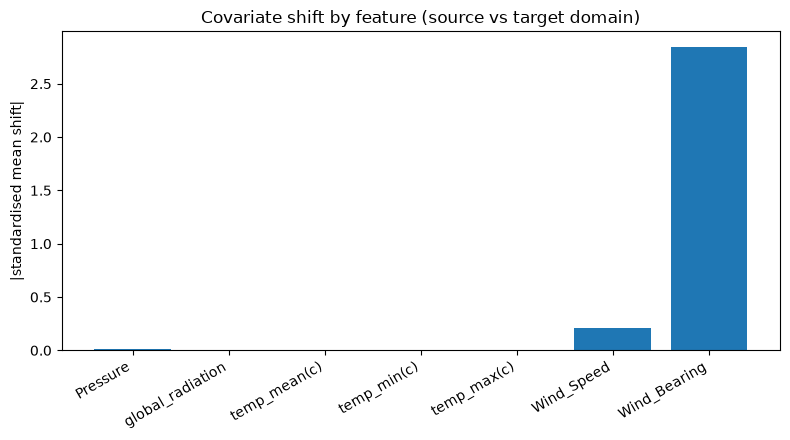

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
stable=[r for r in shift_df.itertuples() if r.std_mean_shift<0.20]
stable_feats=[r.feature for r in stable]
if len(stable_feats)<3: stable_feats=shift_df.sort_values("std_mean_shift").head(3)["feature"].tolist()
print("Stable features (|standardised mean shift|<0.20, or 3 least-shifted):", stable_feats)
def eval_model(feats):
    Xtr,Xte,ytr,yte=train_test_split(src[feats], src[TARGET], test_size=0.25, random_state=42, stratify=src[TARGET])
    m=RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1); m.fit(Xtr,ytr)
    return accuracy_score(yte, m.predict(Xte)), accuracy_score(tgt[TARGET], m.predict(tgt[feats]))
for label, feats in [("All features",FEATURES),("Stable only",stable_feats)]:
    a_src,a_tgt=eval_model(feats); print(f"{label}: source accuracy {a_src:.4f}, target-domain accuracy {a_tgt:.4f}, drop {a_src-a_tgt:.4f}")
plt.bar(shift_df["feature"], shift_df["std_mean_shift"]); plt.xticks(rotation=30, ha="right"); plt.ylabel("|standardised mean shift|"); plt.title("Covariate shift by feature (source vs target domain)"); plt.tight_layout(); plt.show()

## Part 5 — Interpretation

In [4]:
print("INTERPRETATION: Features with large standardised mean shift or tiny KS p-values are unstable across this bearing domain split. Retraining on stable features may lose a little source accuracy but can reduce the source-to-target drop; the table above shows whether that trade-off held in this run.")
print("LIMITATION: This is a bearing-domain shift, not a dated future slice, because the file has no timestamp. Do not present it as a forecast over calendar time.")

INTERPRETATION: Features with large standardised mean shift or tiny KS p-values are unstable across this bearing domain split. Retraining on stable features may lose a little source accuracy but can reduce the source-to-target drop; the table above shows whether that trade-off held in this run.
LIMITATION: This is a bearing-domain shift, not a dated future slice, because the file has no timestamp. Do not present it as a forecast over calendar time.


## Conclusion

See the printed metrics and plots above. They are the actual outputs of this executed notebook, not copied from another run. Limitations stated at the top still apply.